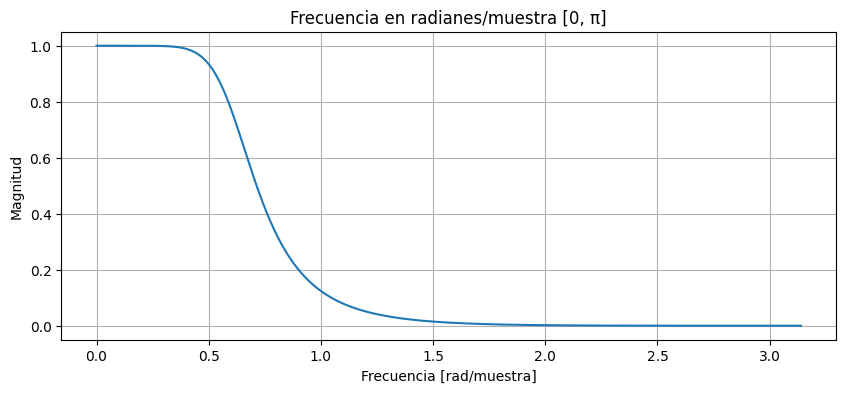

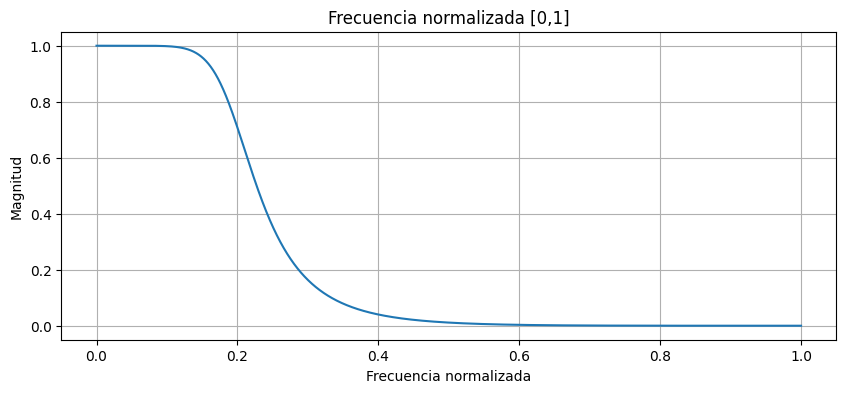

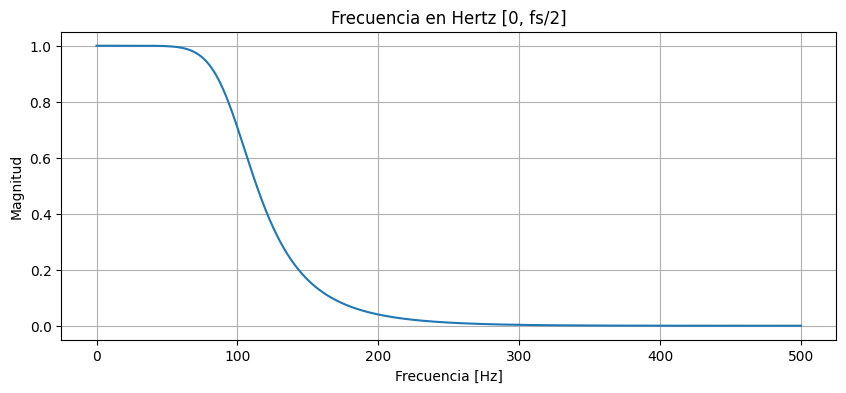

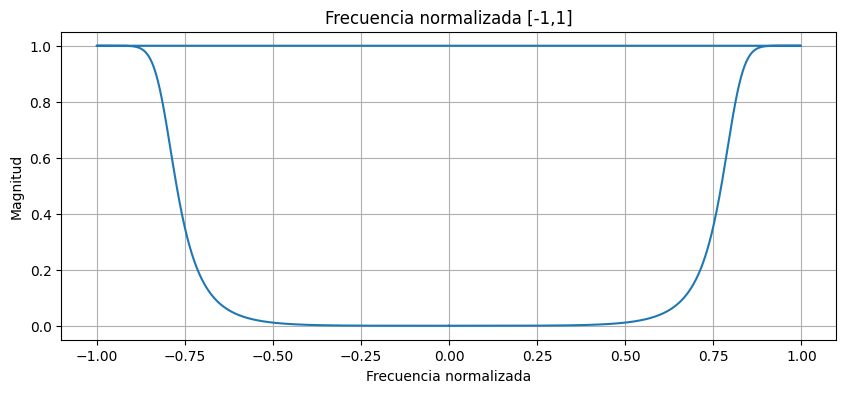

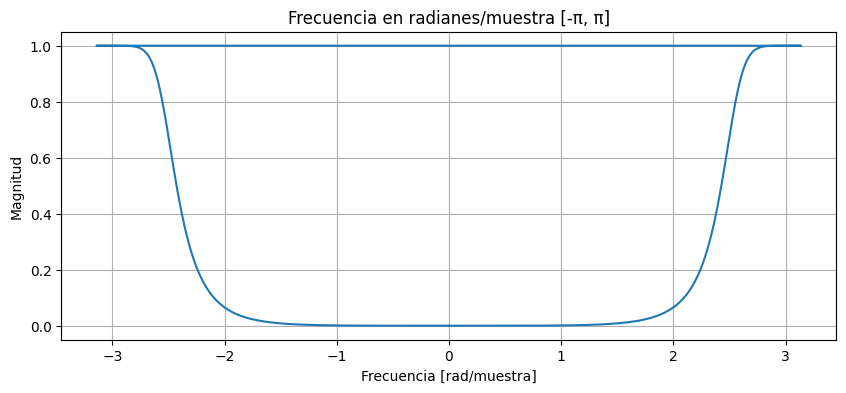

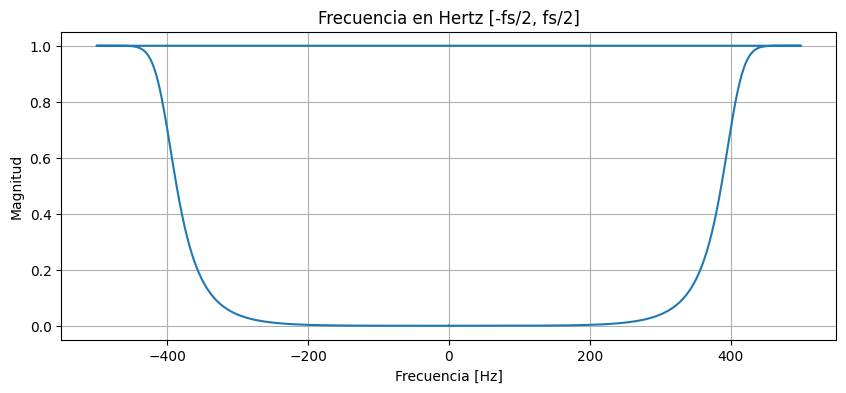

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ============================================================
# EJEMPLO: FILTRO PASABAJOS BUTTERWORTH
# ============================================================

fs = 1000  # Frecuencia de muestreo (Hz)

# Diseño del filtro
b, a = signal.butter(4, 100, btype='low', fs=fs)

# Respuesta en frecuencia
w, h = signal.freqz(b, a, worN=2048)

# ============================================================
# 1. FRECUENCIA EN RADIANES/MUESTRA
# Rango: 0 a pi
# ============================================================

plt.figure(figsize=(10,4))
plt.plot(w, np.abs(h))
plt.title("Frecuencia en radianes/muestra [0, π]")
plt.xlabel("Frecuencia [rad/muestra]")
plt.ylabel("Magnitud")
plt.grid(True)

# ============================================================
# 2. FRECUENCIA NORMALIZADA [0,1]
# 1 corresponde a la frecuencia de Nyquist
# ============================================================

f_norm = w / np.pi

plt.figure(figsize=(10,4))
plt.plot(f_norm, np.abs(h))
plt.title("Frecuencia normalizada [0,1]")
plt.xlabel("Frecuencia normalizada")
plt.ylabel("Magnitud")
plt.grid(True)

# ============================================================
# 3. FRECUENCIA EN HERTZ [0, fs/2]
# ============================================================

f_hz = w * fs / (2*np.pi)

plt.figure(figsize=(10,4))
plt.plot(f_hz, np.abs(h))
plt.title("Frecuencia en Hertz [0, fs/2]")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.grid(True)

# ============================================================
# 4. FRECUENCIA NORMALIZADA [-1,1]
# Muy usada en DSP teórico
# ============================================================

w_shift, h_shift = signal.freqz(b, a, worN=2048, whole=True)

# Shift para centrar DC
w_shift = np.fft.fftshift(w_shift)
h_shift = np.fft.fftshift(h_shift)

# Conversión
f_norm_signed = w_shift / np.pi - 1

plt.figure(figsize=(10,4))
plt.plot(f_norm_signed, np.abs(h_shift))
plt.title("Frecuencia normalizada [-1,1]")
plt.xlabel("Frecuencia normalizada")
plt.ylabel("Magnitud")
plt.grid(True)

# ============================================================
# 5. FRECUENCIA EN RADIANES/MUESTRA [-π, π]
# Muy usada en teoría de Fourier
# ============================================================

w_signed = w_shift - np.pi

plt.figure(figsize=(10,4))
plt.plot(w_signed, np.abs(h_shift))
plt.title("Frecuencia en radianes/muestra [-π, π]")
plt.xlabel("Frecuencia [rad/muestra]")
plt.ylabel("Magnitud")
plt.grid(True)

# ============================================================
# 6. FRECUENCIA EN HERTZ [-fs/2, fs/2]
# Muy usada en FFT centrada
# ============================================================

f_hz_signed = w_signed * fs / (2*np.pi)

plt.figure(figsize=(10,4))
plt.plot(f_hz_signed, np.abs(h_shift))
plt.title("Frecuencia en Hertz [-fs/2, fs/2]")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.grid(True)

plt.show()


===== 1) RAD/MUESTRA [0, π] =====
Conversión a Hz:
f = ω * fs / (2π)

===== 2) NORMALIZADA [0,1] =====
Conversión a Hz:
f = f_norm * (fs/2)

===== 3) HERTZ [0, fs/2] =====
Ya está en Hz

===== 4) NORMALIZADA [-1,1] =====
Conversión a Hz:
f = f_norm_signed * (fs/2)

===== 5) RAD/MUESTRA [-π, π] =====
Conversión a Hz:
f = ω * fs / (2π)

===== 6) HERTZ [-fs/2, fs/2] =====
Ya está en Hz


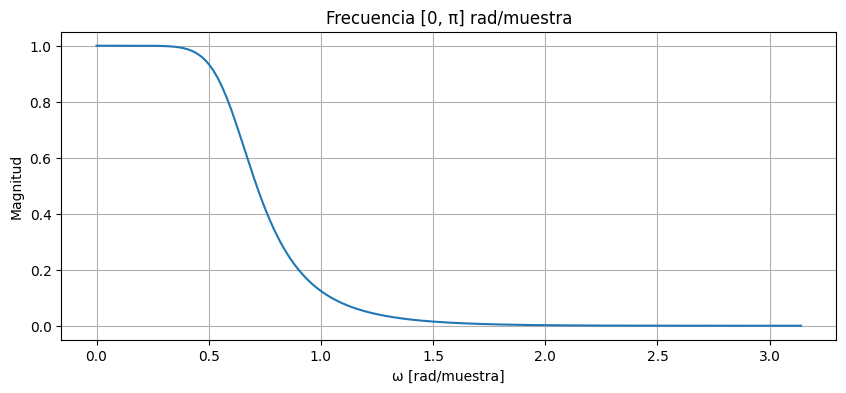

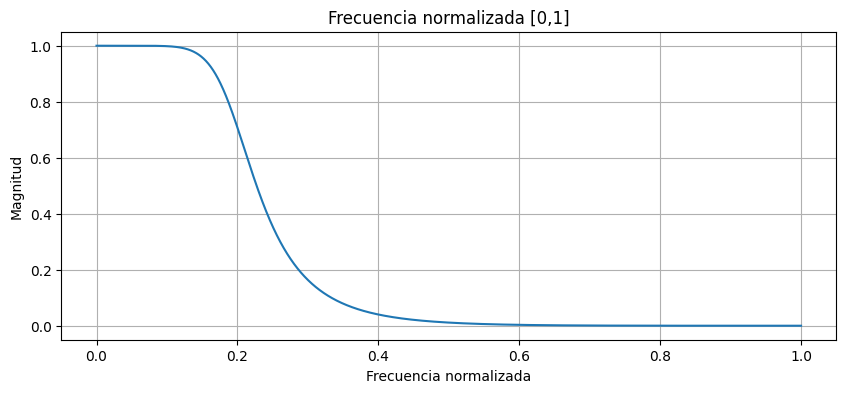

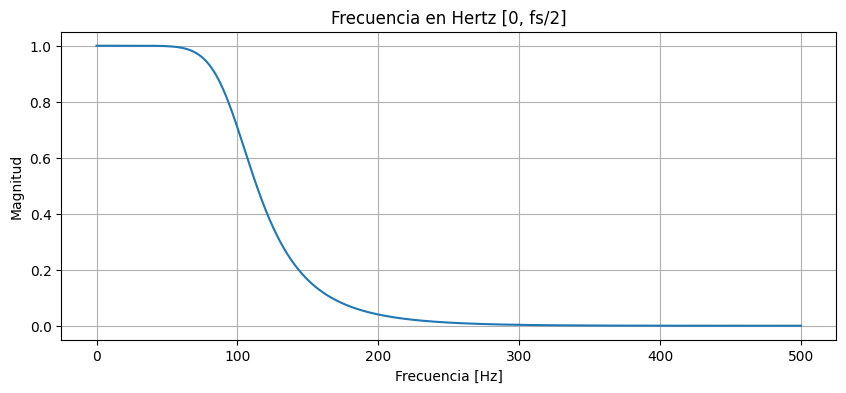

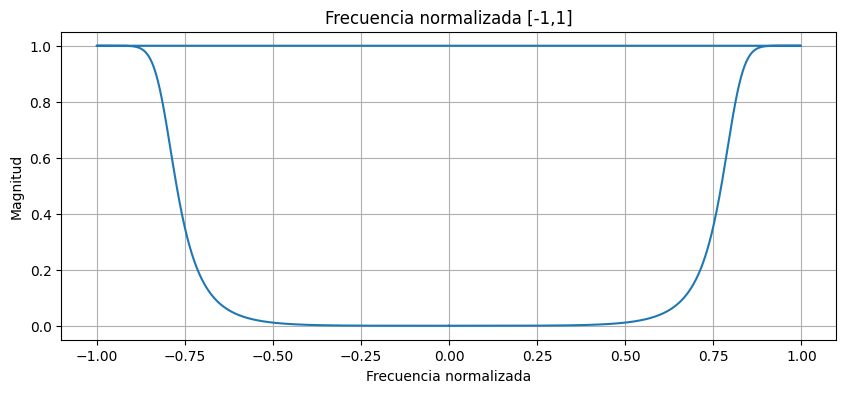

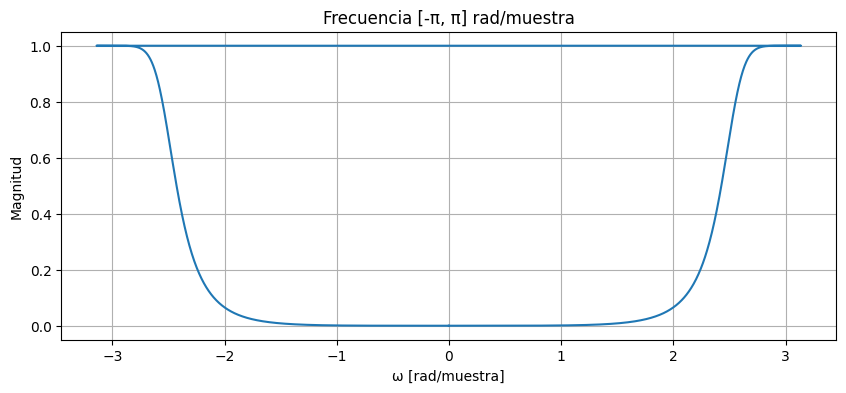

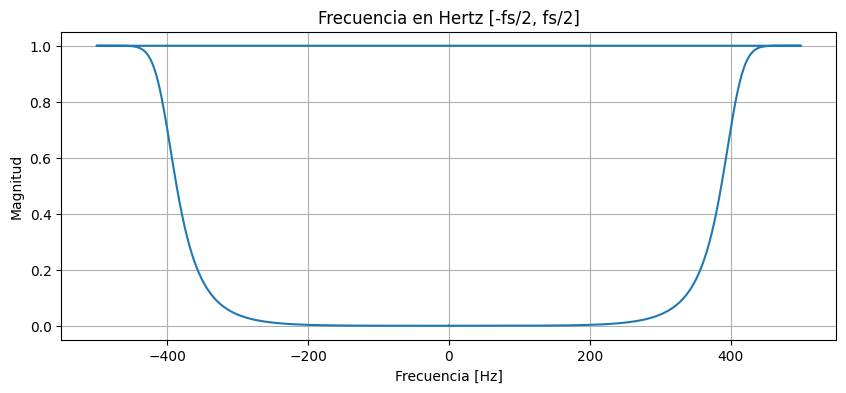


RESUMEN GENERAL

1) RAD/MUESTRA → HZ
   f = ω * fs / (2π)

2) NORMALIZADA [0,1] → HZ
   f = f_norm * (fs/2)

3) NORMALIZADA [-1,1] → HZ
   f = f_norm * (fs/2)

4) HZ → RAD/MUESTRA
   ω = 2πf / fs

5) HZ → NORMALIZADA
   f_norm = f / (fs/2)



In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ============================================================
# PARÁMETROS
# ============================================================

fs = 1000  # Frecuencia de muestreo [Hz]

# ============================================================
# FILTRO DE EJEMPLO
# ============================================================

b, a = signal.butter(4, 100, btype='low', fs=fs)

# Respuesta en frecuencia
w, h = signal.freqz(b, a, worN=2048)

# ============================================================
# 1) RADIANES/MUESTRA [0, π]
# ============================================================

# w YA ESTÁ EN rad/muestra

# Conversión a Hz
f_hz_from_rad = w * fs / (2*np.pi)

plt.figure(figsize=(10,4))
plt.plot(w, np.abs(h))
plt.title("Frecuencia [0, π] rad/muestra")
plt.xlabel("ω [rad/muestra]")
plt.ylabel("Magnitud")
plt.grid(True)

print("\n===== 1) RAD/MUESTRA [0, π] =====")
print("Conversión a Hz:")
print("f = ω * fs / (2π)")

# ============================================================
# 2) FRECUENCIA NORMALIZADA [0,1]
# ============================================================

# Normalización respecto a Nyquist
f_norm = w / np.pi

# Conversión a Hz
f_hz_from_norm = f_norm * (fs/2)

plt.figure(figsize=(10,4))
plt.plot(f_norm, np.abs(h))
plt.title("Frecuencia normalizada [0,1]")
plt.xlabel("Frecuencia normalizada")
plt.ylabel("Magnitud")
plt.grid(True)

print("\n===== 2) NORMALIZADA [0,1] =====")
print("Conversión a Hz:")
print("f = f_norm * (fs/2)")

# ============================================================
# 3) FRECUENCIA EN HERTZ [0, fs/2]
# ============================================================

f_hz = w * fs / (2*np.pi)

plt.figure(figsize=(10,4))
plt.plot(f_hz, np.abs(h))
plt.title("Frecuencia en Hertz [0, fs/2]")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.grid(True)

print("\n===== 3) HERTZ [0, fs/2] =====")
print("Ya está en Hz")

# ============================================================
# 4) FRECUENCIA NORMALIZADA [-1,1]
# ============================================================

w_whole, h_whole = signal.freqz(b, a, worN=2048, whole=True)

# Centrado
w_shift = np.fft.fftshift(w_whole)
h_shift = np.fft.fftshift(h_whole)

# Conversión a normalizada [-1,1]
f_norm_signed = w_shift / np.pi - 1

# Conversión a Hz
f_hz_from_norm_signed = f_norm_signed * (fs/2)

plt.figure(figsize=(10,4))
plt.plot(f_norm_signed, np.abs(h_shift))
plt.title("Frecuencia normalizada [-1,1]")
plt.xlabel("Frecuencia normalizada")
plt.ylabel("Magnitud")
plt.grid(True)

print("\n===== 4) NORMALIZADA [-1,1] =====")
print("Conversión a Hz:")
print("f = f_norm_signed * (fs/2)")

# ============================================================
# 5) RADIANES/MUESTRA [-π, π]
# ============================================================

w_signed = w_shift - np.pi

# Conversión a Hz
f_hz_from_signed_rad = w_signed * fs / (2*np.pi)

plt.figure(figsize=(10,4))
plt.plot(w_signed, np.abs(h_shift))
plt.title("Frecuencia [-π, π] rad/muestra")
plt.xlabel("ω [rad/muestra]")
plt.ylabel("Magnitud")
plt.grid(True)

print("\n===== 5) RAD/MUESTRA [-π, π] =====")
print("Conversión a Hz:")
print("f = ω * fs / (2π)")

# ============================================================
# 6) HERTZ [-fs/2, fs/2]
# ============================================================

f_hz_signed = w_signed * fs / (2*np.pi)

plt.figure(figsize=(10,4))
plt.plot(f_hz_signed, np.abs(h_shift))
plt.title("Frecuencia en Hertz [-fs/2, fs/2]")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.grid(True)

print("\n===== 6) HERTZ [-fs/2, fs/2] =====")
print("Ya está en Hz")

plt.show()

# ============================================================
# RESUMEN DE CONVERSIONES
# ============================================================

print("\n===================================================")
print("RESUMEN GENERAL")
print("===================================================")

print("""
1) RAD/MUESTRA → HZ
   f = ω * fs / (2π)

2) NORMALIZADA [0,1] → HZ
   f = f_norm * (fs/2)

3) NORMALIZADA [-1,1] → HZ
   f = f_norm * (fs/2)

4) HZ → RAD/MUESTRA
   ω = 2πf / fs

5) HZ → NORMALIZADA
   f_norm = f / (fs/2)
""")